In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import new_calcium_model, simulate_dipole, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology
 
# import pandas as pd
from scipy import signal
import sys
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/compare_jones2009'

In [2]:
def stim_dpl(net, stim_cell='L5_pyramidal'):

    window_len, scaling_factor = 30, 1

    net.clear_connectivity()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2400,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = 2.5
    t0 = 20

    for i in range(1):
        net.add_tonic_bias(cell_type=stim_cell,section='soma',bias_name='pulse_'+str(i),amplitude=ampl,t0=t0+i*10,tstop=t0+i*10+20)

    dpl = simulate_dipole(net, tstop=150, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='none')
    smooth_dpl = dpl[0].copy()
    smooth_dpl.smooth(window_len).scale(scaling_factor)

    return net, dpl, smooth_dpl


def plot_dpl_l5(net, dpl, smooth_dpl, axs, gid, row_idx):

    timevec = net.cell_response.times

    v = net.cell_response.vsec[0][gid]['soma']
    v_apcl = net.cell_response.vsec[0][gid]['apical_tuft']
    axs[row_idx,0].plot(timevec, v, color='k', linewidth=2, alpha=0.5)
    axs[row_idx,0].plot(timevec, v_apcl, color='k', linewidth=2)

    axs[row_idx,0].set_ylabel('voltage $\mu V$')

    ca_soma = net.cell_response.ca[0][gid]['soma']

    ca= net.cell_response.ca[0][gid]['apical_tuft']

    axs[row_idx,1].plot(timevec, ca_soma, label='soma', color='k', linewidth=2, alpha=0.5)
    axs[row_idx,1].plot(timevec, ca, label='apical tuft', color='k', linewidth=2)
    axs[row_idx,1].set_ylabel('calcium concentration (mM)')
    axs[row_idx,1].legend(loc='upper right', fontsize=8)

    axs[row_idx,2].plot(timevec, dpl[0].data['L5'], label='unsmoothed', color='k', linewidth=2, alpha=0.5)
    axs[row_idx,2].plot(timevec, smooth_dpl.data['L5'], label='smoothed', color='k', linewidth=2)
    axs[row_idx,2].legend(loc='upper right', fontsize=8)
    axs[row_idx,2].set_title('')
    axs[row_idx,2].set_ylabel('Dipole moment (nAm)')
    axs[row_idx,2].set_ylim([-0.002, 0.004])

    for ax in axs[row_idx]:
        ax.set_xlabel('time (s)')

    return axs



def plot_dpl_l23(net, dpl, smooth_dpl, axs, gid, row_idx):

    timevec = net.cell_response.times

    v = net.cell_response.vsec[0][gid]['soma']
    v_apcl = net.cell_response.vsec[0][gid]['apical_tuft']
    axs[row_idx,0].plot(timevec, v, color='k', linewidth=2, alpha=0.5)
    axs[row_idx,0].plot(timevec, v_apcl, color='k', linewidth=2)

    axs[row_idx,0].set_ylabel('voltage $\mu V$')

    axs[row_idx,1].plot(timevec, dpl[0].data['L2'], label='unsmoothed', color='k', linewidth=2, alpha=0.5)
    axs[row_idx,1].plot(timevec, smooth_dpl.data['L2'], label='smoothed', color='k', linewidth=2)
    axs[row_idx,1].legend(loc='upper right', fontsize=8)
    axs[row_idx,1].set_title('')
    axs[row_idx,1].set_ylabel('Dipole moment (nAm)')
    axs[row_idx,1].set_ylim([-0.001, 0.0015])

    for ax in axs[row_idx]:
        ax.set_xlabel('time (s)')

    return axs

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn('No connections instantiated in network. Consider using '


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


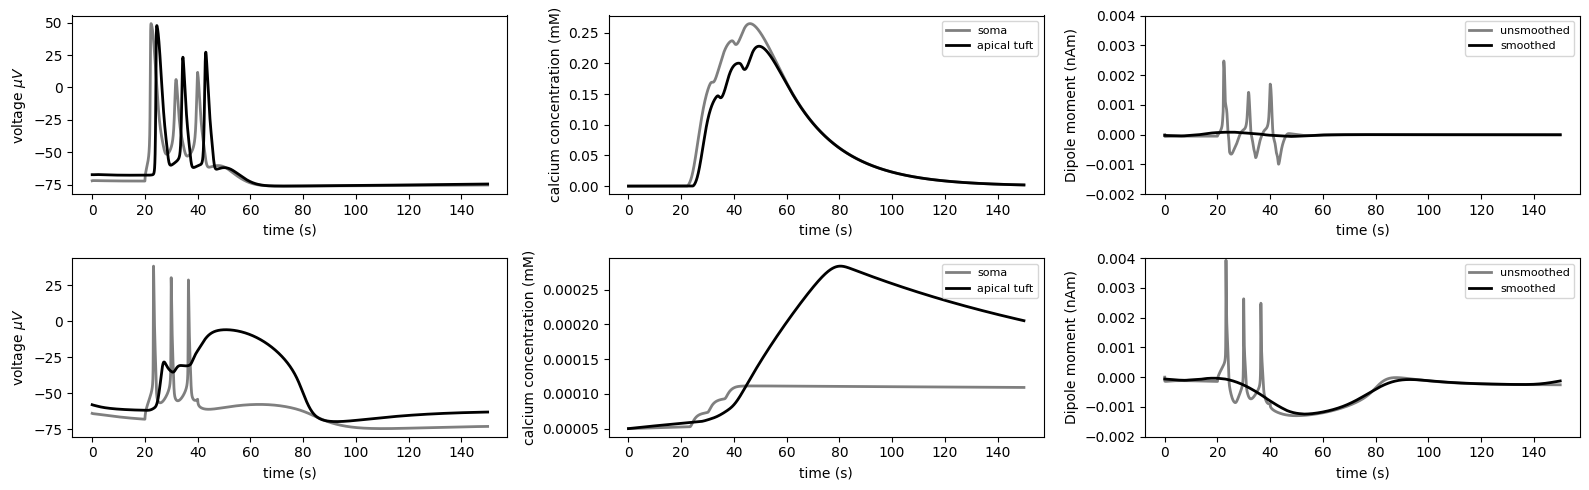

In [3]:
fig, axs = plt.subplots(2,3,figsize=(16,5))
gid = 3

net, dpl, smooth_dpl = stim_dpl(jones_2009_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal')

plot_dpl_l5(net, dpl, smooth_dpl, axs, gid, 0)

net, dpl, smooth_dpl = stim_dpl(new_calcium_model(mesh_shape=(1,1)), stim_cell='L5_pyramidal')

plot_dpl_l5(net, dpl, smooth_dpl, axs, gid, 1)

fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l5.pdf'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l5.png'), dpi=300, bbox_inches='tight')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...


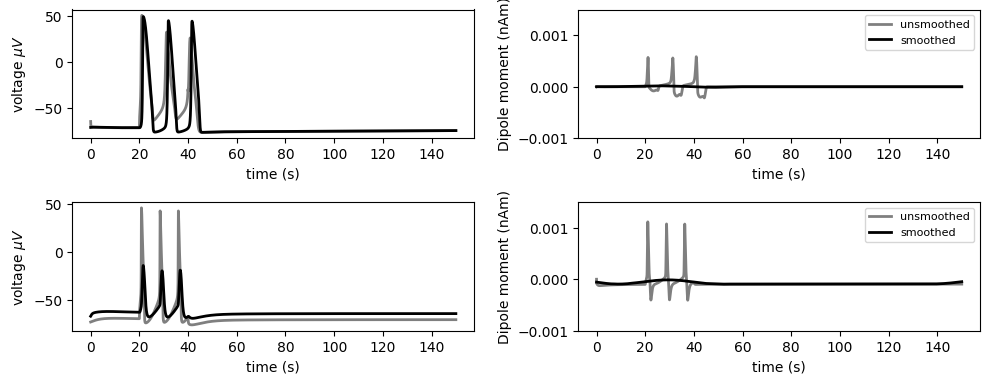

In [4]:
fig, axs = plt.subplots(2,2,figsize=(10,4))
gid = 1

net, dpl, smooth_dpl = stim_dpl(jones_2009_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal')

plot_dpl_l23(net, dpl, smooth_dpl, axs, gid, 0)

net, dpl, smooth_dpl = stim_dpl(new_calcium_model(mesh_shape=(1,1)), stim_cell='L2_pyramidal')

plot_dpl_l23(net, dpl, smooth_dpl, axs, gid, 1)

fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l23.pdf'), dpi=300, bbox_inches='tight')
fig.savefig(os.path.join(pathfig, 'compare_jones2009_new_model_l23.png'), dpi=300, bbox_inches='tight')